# Entraînement de la politique RL (SAC) sur le modèle LSTM

## Lien entre le LSTM et SAC

Le projet utilise **deux réseaux de neurones, qui jouent deux rôles différents** :

| | LSTM (notebook 01) | Politique SAC (ce notebook) |
|---|---|---|
| Rôle | **Modèle du drone** : simulateur | **Contrôleur** : pilote |
| Entrée → sortie | commande $u$ → accélération $a_z$ | observation (erreur, vitesse...) → commande $u$ |
| Appris par | apprentissage supervisé sur les données CSV | renforcement, par essais-erreurs dans le simulateur |
| Pendant ce notebook | **figé** (poids non modifiés) | **entraîné** |

**Pourquoi passer par le LSTM ?** On ne peut pas faire des milliers d'essais sur un vrai drone : il s'écraserait. Le LSTM, identifié sur les données, sert de **simulateur rapide et gratuit**. SAC peut y faire environ 500 vols en quelques minutes.

**SAC (Soft Actor-Critic) en bref :**
- un **actor**, la politique : il propose $u$ ;
- deux **critics** : ils estiment la récompense future $Q(s, u)$ et indiquent à l'actor dans quel sens s'améliorer ;
- un **bonus d'entropie** : il pousse l'agent à explorer au début ;
- un **replay buffer** : les transitions passées sont réutilisées, ce qui économise les données.

**Conséquence importante :** la politique ne peut être bonne que si le LSTM l'est. Elle apprend à piloter *notre modèle*, pas le vrai drone. Le test final sur `UAV_model.slx` (dans MATLAB) mesure cet écart entre simulation et réalité (sim-to-real gap).

## Étape 1 : entraîner l'agent SAC

**L'environnement `DroneEnv`** ([src/env.py](../src/env.py)) simule un vol de 10 s (200 pas de Ts = 0,05 s). À chaque pas :
1. l'agent choisit une commande $u \in [0, 0{,}8]$ ;
2. le LSTM prédit l'accélération $a_z$ ;
3. on intègre : $v_z \leftarrow v_z + T_s\,a_z$, puis $z \leftarrow z + T_s\,v_z$ ;
4. on calcule la récompense : $r = e^{-(e/0{,}15)^2} - 0{,}05\,\min(v_z^2, 4) - 0{,}05\,(u - u_{prev})^2$, avec $e = z_{ref} - z$.
   Elle vaut presque 1 sur la consigne, et elle est pénalisée si la vitesse est grande ou si $u$ change brusquement.

**Observation** (ce que voit l'agent, 5 valeurs) : $[\,z_{ref} - z,\; v_z,\; a_z/10,\; u_{prev},\; z_{ref}\,]$.

**Consigne** : 0 m sur la plateforme, puis 0,5 m à partir de 1 s, puis −0,25 m (atterrissage au sol) à partir de 5 s.

**L'agent** : `SAC("MlpPolicy", net_arch=[64, 64])`. La politique est un réseau à 2 couches cachées de 64 neurones (5 observations en entrée, $u$ en sortie). On l'entraîne sur 100 000 pas, soit environ 500 vols simulés. La récompense maximale est d'environ 200 par vol (200 pas × 1). Le modèle est enregistré dans `models/sac_drone.zip`.

### La fonction de récompense

À chaque pas de 0,05 s, l'agent reçoit :

$$
r = \underbrace{e^{-(e/0{,}15)^2}}_{\text{suivre la consigne}} \;-\; \underbrace{0{,}05\,\min(v_z^2,\,4)}_{\text{voler doucement}} \;-\; \underbrace{0{,}2\,(u - u_{prev})^2}_{\text{commande lisse}}
\qquad \text{avec } e = z_{ref} - z
$$

| Terme | Rôle | Valeurs |
|---|---|---|
| $e^{-(e/0{,}15)^2}$ | **Objectif principal** : être sur la consigne. C'est une cloche centrée sur $e = 0$, de largeur ~0,15 m. | $e = 0$ → 1 ; $e = 0{,}15$ m → 0,37 ; $e = 0{,}3$ m → 0,02 |
| $0{,}05\,\min(v_z^2, 4)$ | Pénalise la vitesse : vol calme, **atterrissage lent**. Le plafond à 4 (soit $\lvert v_z \rvert = 2$ m/s) évite qu'un instant rapide écrase tout le reste. | au plus −0,2 par pas |
| $0{,}2\,(u - u_{prev})^2$ | Pénalise les changements brusques de commande, pour éviter les oscillations de $u$ (mauvaises pour les moteurs). | sauts de 0,1 → −0,002 |

**Fin d'épisode :** si $\lvert e \rvert > 2$ m, le drone est considéré comme perdu et le vol s'arrête (`terminated`). Comme la récompense par pas est positive, s'arrêter tôt fait perdre des points : l'agent apprend à rester en vol.

**Score maximal :** environ 200 par vol (200 pas × 1), ce qui rend la learning curve facile à lire.

#### Pourquoi ce choix ?

Première version testée : une pénalité quadratique classique, $r = -(e^2 + 0{,}1\,v_z^2 + 0{,}01\,\Delta u^2)$. **L'agent n'apprenait presque rien** : la récompense moyenne stagnait autour de −27.
- La récompense est toujours négative : l'agent n'a pas de « but » à atteindre, il cherche seulement à perdre le moins possible.
- Près de la consigne, $e^2$ est minuscule ($0{,}1^2 = 0{,}01$) : l'agent ne fait presque pas la différence entre « proche » et « dessus ».

Avec la cloche, la récompense **monte nettement** quand le drone s'approche à moins de ~0,15 m. C'est un signal clair à poursuivre, et la récompense moyenne est passée de −27 à environ 150 sur 200.

Les poids (0,15 ; 0,05 ; 0,2) sont choisis **à la main**. On garde les pénalités petites devant le terme principal (au plus 1 par pas), pour que suivre la consigne reste la priorité. On les ajuste en regardant les trajectoires (étape 2).

#### Robustesse (domain randomization)

Pendant l'entraînement (`randomize=True`), chaque vol ajoute à $a_z$ un **biais constant** tiré au hasard dans $[-1, 1]$ m/s², ainsi qu'un **bruit** d'écart-type 0,1 m/s². L'agent apprend ainsi à voler même si le modèle est un peu faux, ce qui prépare le passage au vrai simulateur `UAV_model.slx`. C'est aussi l'intérêt de l'**intégrale de l'erreur** $I$ dans l'observation : comme le terme I d'un PID, elle permet de compenser un biais constant.

In [1]:
import sys; sys.path.append("../..")
from stable_baselines3 import SAC
from src.env import DroneEnv

env = DroneEnv(model_path="../../models/lstm_az.ckpt", scaler_path="../../models/lstm_az_scaler.json")

agent = SAC("MlpPolicy", env, policy_kwargs=dict(net_arch=[64, 64]),
            verbose=1, tensorboard_log="../../results/tensorboard")
agent.learn(total_timesteps=100_000)      # 100 000 pas = 500 vols simulés
agent.save("../../models/sac_drone")

Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Logging to ../results/tensorboard/SAC_8
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 20.8     |
|    ep_rew_mean     | -0.709   |
| time/              |          |
|    episodes        | 4        |
|    fps             | 5160     |
|    time_elapsed    | 0        |
|    total_timesteps | 83       |
---------------------------------
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 20.1     |
|    ep_rew_mean     | -0.667   |
| time/              |          |
|    episodes        | 8        |
|    fps             | 1088     |
|    time_elapsed    | 0        |
|    total_timesteps | 161      |
| train/             |          |
|    actor_loss      | -1.08    |
|    critic_loss     | 0.142    |
|    ent_coef        | 0.982    |
|    ent_coef_loss   | -0.03    |
|    learning_rate   | 0.0003   |
|    n_updates  

## Étape 2 : tester la politique entraînée

On fait **un vol de 10 s** dans l'environnement avec l'agent entraîné. `deterministic=True` coupe l'exploration au hasard : l'agent applique sa meilleure action.

On trace :
- **en haut** : l'altitude $z$ comparée à la consigne. Est-ce que le drone suit la mission ?
- **en bas** : la commande $u$. Est-elle calme ou oscille-t-elle ? Le vol stationnaire correspond à $u \approx 0{,}4$.

Il faut toujours regarder la trajectoire, pas seulement la récompense : une bonne récompense peut cacher un comportement absurde (*reward hacking*).

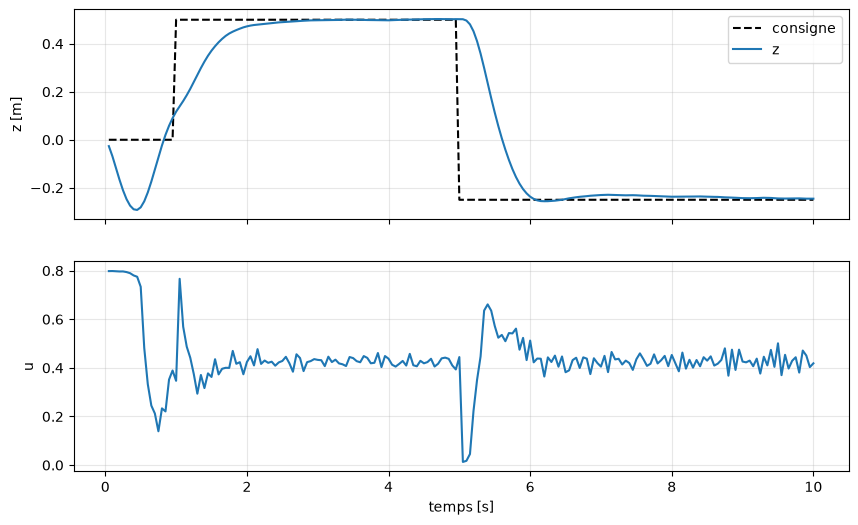

In [2]:
import numpy as np, matplotlib.pyplot as plt

obs, info = env.reset()
t, z, z_ref, u = [], [], [], []
for _ in range(200):
    action, _ = agent.predict(obs, deterministic=True)     # politique sans exploration
    obs, r, term, trunc, info = env.step(action)
    m = info["m"]
    t.append(m["t"]); z.append(m["z"]); z_ref.append(m["z_ref"]); u.append(m["u_prev"])
    if term: break

fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax[0].plot(t, z_ref, "k--", label="consigne"); ax[0].plot(t, z, label="z")
ax[0].set_ylabel("z [m]"); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].plot(t, u); ax[1].set_ylabel("u"); ax[1].set_xlabel("temps [s]"); ax[1].grid(alpha=0.3)
plt.show()

## Étape 3 : exporter la politique vers MATLAB

`export_for_matlab` (`src/export_policy.py`) écrit deux fichiers dans ce dossier :
- **`policy.mat`** : les poids du réseau 64×64 ;
- **`traj_model.mat`** : un vol de référence simulé en Python.

Détails importants :
- Ils sont écrits à côté de `EINT_RL_eval.m` et `rl_controller.m`, qui les lisent.
- On utilise un environnement **sans bruit** (`noise=0.0`). MATLAB peut ainsi vérifier qu'il retrouve **exactement** le même vol que Python, ce qui prouve que `rl_controller.m` (observation, consigne) est identique au code Python.

**Étape suivante, dans MATLAB :** lancer `EINT_RL_eval`. La politique vole alors sur le vrai simulateur `UAV_model.slx`.

In [3]:
import os, sys
sys.path.append("../../src")
from export_policy import export_for_matlab

# policy.mat et traj_model.mat sont écrits dans ce dossier, à côté de EINT_RL_eval.m
env_export = DroneEnv(model_path="../../models/lstm_az.ckpt",
                      scaler_path="../../models/lstm_az_scaler.json", randomize=False)
export_for_matlab(agent, env_export)

policy.mat and traj_model.mat written (200 steps): now run EINT_RL_eval in MATLAB.
